Hubungkan Colab ke Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


OPTIONAL DIJALANKAN 
Hapus Folder dataset_hibrida yang Lama (karena terdeteksi 3 kelas)
Dan cek isi /content

In [11]:
import shutil
import os

# Hapus folder dataset_hibrida yang lama beserta seluruh isinya
# folder_path = '/content/dataset_hibrida'

# if os.path.exists(folder_path):
#     shutil.rmtree(folder_path)
#     print(f"✅ Folder {folder_path} berhasil dihapus!")
# else:
#     print("ℹ️ Folder tidak ditemukan, tidak perlu dihapus.")

# Cek apakah sudah benar-benar hilang
print("Isi /content sekarang:", os.listdir('/content'))

Isi /content sekarang: ['.config', 'drive', 'dataset_hibrida', 'sample_data']


Ekstrak Dataset di Colab

In [10]:
import zipfile
import os

# Path ke file ZIP di Google Drive
zip_path = '/content/drive/MyDrive/skripsi_sampah/dataset_hibrida.zip'
extract_path = '/content'  # Ekstrak langsung ke /content

# Ekstrak ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Ekstrak selesai!")

# Cek hasil ekstrak
print("Isi /content sekarang:", os.listdir('/content'))
print("Isi /content/dataset_hibrida:", os.listdir('/content/dataset_hibrida'))

✅ Ekstrak selesai!
Isi /content sekarang: ['.config', 'drive', 'dataset_hibrida', 'sample_data']
Isi /content/dataset_hibrida: ['anorganik', 'organik']


Memastikan Struktur

In [12]:
import os
import shutil

# Cek apakah folder dataset_hibrida ada dan isinya benar
if os.path.exists('/content/dataset_hibrida'):
    contents = os.listdir('/content/dataset_hibrida')
    if 'organik' in contents and 'anorganik' in contents:
        print("✅ Struktur dataset BENAR!")
        print(f"📁 Isi: {contents}")
    else:
        print("❌ Struktur dataset SALAH! Isi:", contents)
else:
    print("❌ Folder dataset_hibrida tidak ditemukan!")

✅ Struktur dataset BENAR!
📁 Isi: ['anorganik', 'organik']


Import Library yang Dibutuhkan

In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np
import os
import pathlib
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

Load Dataset dari Folder

In [14]:
# Tentukan path ke folder dataset
data_dir = pathlib.Path('/content/dataset_hibrida')

# Parameter
batch_size = 32
img_height = 224
img_width = 224
validation_split = 0.2  # 20% data untuk validasi

# Load data training
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=validation_split,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

# Load data validasi
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=validation_split,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

# Lihat nama kelas
class_names = train_ds.class_names
print(f"Kelas yang terdeteksi: {class_names}")
# Output yang diharapkan: ['anorganik', 'organik'] atau ['organik', 'anorganik']

Found 1478 files belonging to 2 classes.
Using 1183 files for training.
Found 1478 files belonging to 2 classes.
Using 295 files for validation.
Kelas yang terdeteksi: ['anorganik', 'organik']


Pratinjau Data (Opsional)

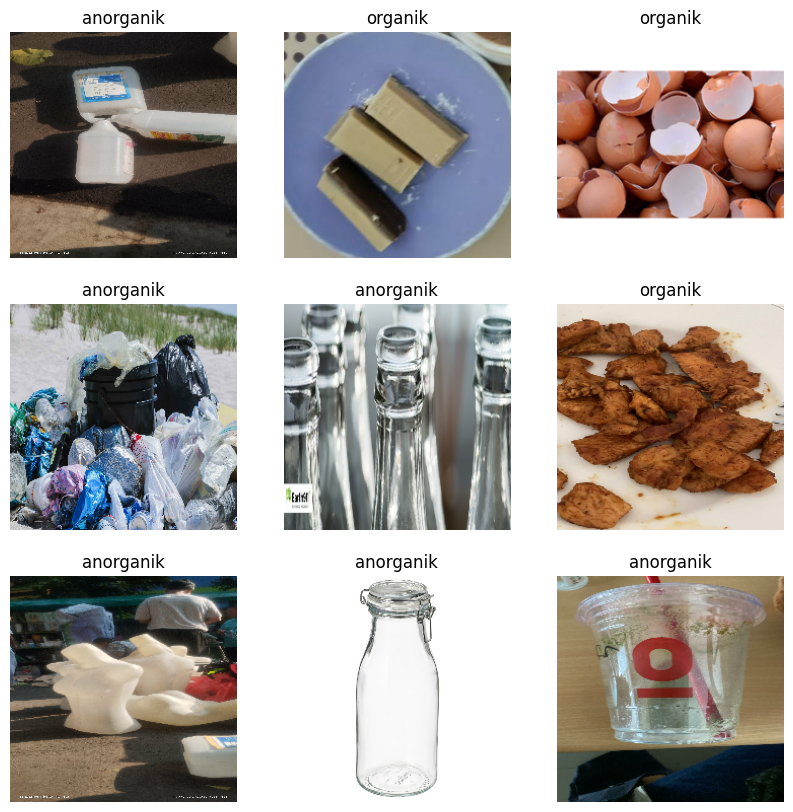

In [18]:
# Tampilkan 9 gambar pertama dari dataset
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

Normalisasi & Optimasi Performa

In [19]:
AUTOTUNE = tf.data.AUTOTUNE

# Normalisasi pixel dari 0-255 menjadi 0-1
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# Cache & prefetch untuk percepat training
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Data Augmentasi (Opsional, tapi sangat disarankan) utk membantu model lebih general dan mengurangi overfitting, terutama jika dataset tidak terlalu besar.

In [20]:
# Buat layer augmentasi
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

# Terapkan augmentasi ke training data
train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y))

BANGUN MODEL DENGAN TRANSFER LEARNING

Load MobileNetV2 Pre-trained

In [21]:
IMG_SHAPE = (img_height, img_width, 3)

# Load MobileNetV2 tanpa lapisan klasifikasi (include_top=False)
base_model = MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights='imagenet'
)

# Freeze semua layer base_model agar tidak ikut dilatih
base_model.trainable = False

# Lihat ringkasan arsitektur
base_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

Tambahkan Lapisan Klasifikasi Sendiri

In [22]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),  # Mencegah overfitting
    layers.Dense(len(class_names), activation='softmax')
])

# Lihat ringkasan model
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,210 (9.24 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Compile Model

In [23]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

LATIH MODEL

Tentukan Callback (Penghenti Otomatis)

In [24]:
# EarlyStopping: berhenti jika akurasi validasi tidak naik setelah 5 epoch
early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=5,
    restore_best_weights=True
)

# ReduceLR: turunkan learning rate jika loss validasi stuck
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7
)

Jalankan Proses Training

In [25]:
epochs = 20  # Bisa coba 15-25

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.8698 - loss: 0.3093 - val_accuracy: 0.8712 - val_loss: 0.2710 - learning_rate: 0.0010
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 395ms/step - accuracy: 0.9637 - loss: 0.1045 - val_accuracy: 0.9627 - val_loss: 0.1042 - learning_rate: 0.0010
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 394ms/step - accuracy: 0.9755 - loss: 0.0706 - val_accuracy: 0.9797 - val_loss: 0.0577 - learning_rate: 0.0010
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 14s 390ms/step - accuracy: 0.9780 - loss: 0.0721 - val_accuracy: 0.9559 - val_loss: 0.1216 - learning_rate: 0.0010
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 392ms/step - accuracy: 0.9890 - loss: 0.0384 - val_accuracy: 0.9695 - val_loss: 0.1059 - learning_rate: 0.0010
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 392ms/step - accuracy: 0.9899 - loss: 0.0340 - val_accuracy: 0.9525 - val_loss: 0.1275 - learning_rate: 0.0010
Epoch 7/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 393ms/step - accuracy: 0.9899 - loss: 0.031

Plot Grafik Akurasi & Loss

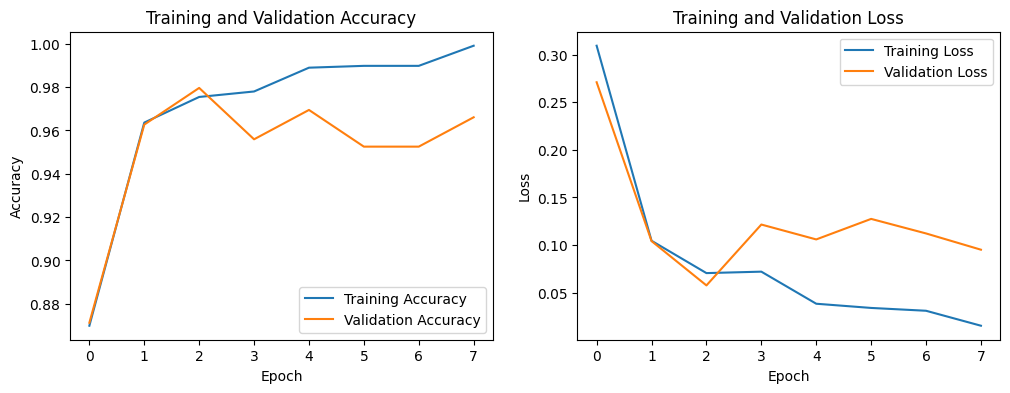

In [26]:
# Akurasi
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()

EVALUASI MODEL

Hitung Akurasi Akhir

In [27]:
loss, accuracy = model.evaluate(val_ds)
print(f'Akurasi pada data validasi: {accuracy:.2%}')

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9797 - loss: 0.0577
Akurasi pada data validasi: 97.97%


Confusion Matrix

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


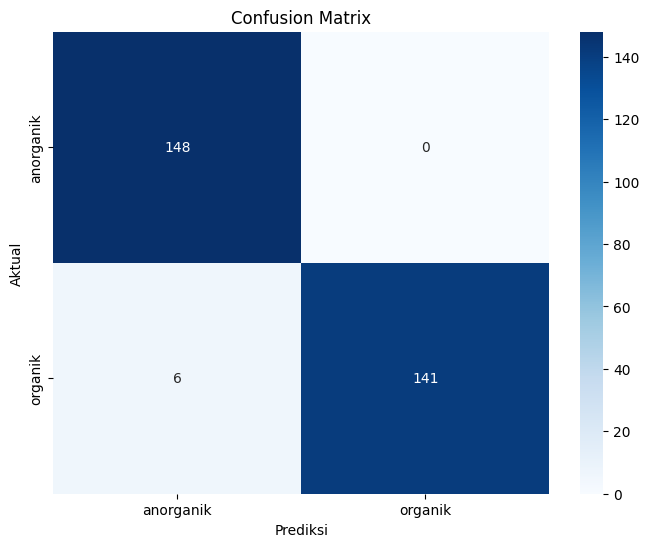


Classification Report:
              precision    recall  f1-score   support

   anorganik       0.96      1.00      0.98       148
     organik       1.00      0.96      0.98       147

    accuracy                           0.98       295
   macro avg       0.98      0.98      0.98       295
weighted avg       0.98      0.98      0.98       295



In [28]:
# Ambil prediksi dari data validasi
y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

# Buat confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix')
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

SIMPAN MODEL dan KONVERSI KE TFLITE

Simpan Model

In [29]:
# Simpan dalam format SavedModel
model.export('saved_model')
print("Model berhasil disimpan di folder 'saved_model'")

Saved artifact at 'saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_159')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  139767319370576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319366160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319365776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319366352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319364432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319364816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319363664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319377104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319363856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319366736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139767319367504

Konversi ke TensorFlow Lite

In [30]:
# Konversi ke TFLite
converter = tf.lite.TFLiteConverter.from_saved_model('saved_model')
tflite_model = converter.convert()

# Simpan file .tflite
tflite_path = '/content/drive/MyDrive/skripsi_sampah/model_sampah.tflite'
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

print(f"Model .tflite berhasil disimpan di: {tflite_path}")

# Cek ukuran file
import os
size_mb = os.path.getsize(tflite_path) / (1024 * 1024)
print(f"Ukuran file .tflite: {size_mb:.2f} MB")

Model .tflite berhasil disimpan di: /content/drive/MyDrive/skripsi_sampah/model_sampah.tflite
Ukuran file .tflite: 9.08 MB


Buat File Label (Opsional)

In [31]:
# Buat file labels.txt untuk aplikasi Android
labels_path = '/content/drive/MyDrive/skripsi_sampah/labels.txt'
with open(labels_path, 'w') as f:
    for label in class_names:
        f.write(label + '\n')

print(f"File labels.txt berhasil dibuat di: {labels_path}")

File labels.txt berhasil dibuat di: /content/drive/MyDrive/skripsi_sampah/labels.txt


DOWNLOAD MODEL DI DRIVE dan MASUKIN KE PROJEK ANDROID

Cek Ukuran Input Model

In [3]:
import tensorflow as tf

# Load model .tflite
interpreter = tf.lite.Interpreter(model_path='/content/drive/MyDrive/skripsi_sampah/model_sampah.tflite')
interpreter.allocate_tensors()

# Dapatkan detail input
input_details = interpreter.get_input_details()
print(f"Input shape: {input_details[0]['shape']}")
print(f"Input type: {input_details[0]['dtype']}")

Input shape: [  1 224 224   3]
Input type: <class 'numpy.float32'>


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
